# EcoFOCIpy ADCP QC - 25CKP-1A

- mostly remove >500 cm/s flows in u/v


In [9]:
import xarray as xa
import numpy as np

import matplotlib.pyplot as plt

from EcoFOCIpy.plots import TimeSeriesStickPlot

In [10]:
xdf = xa.load_dataset('25ckp1a_0032m.trimmed.nc')

In [11]:
len(xdf.depth)

22

/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() shoul

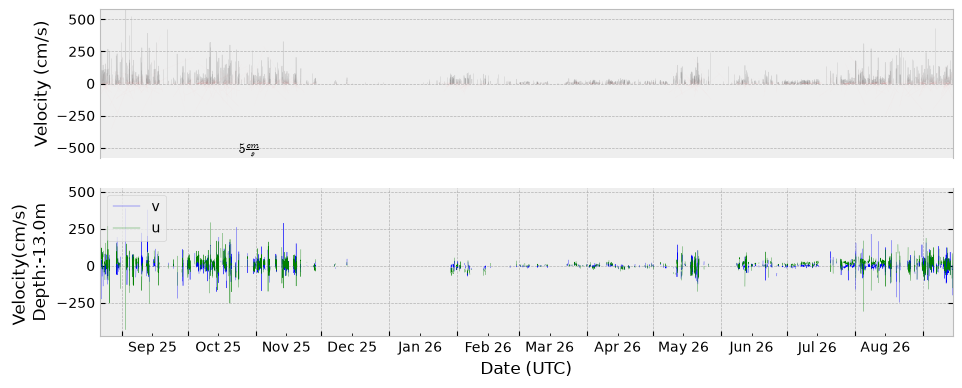

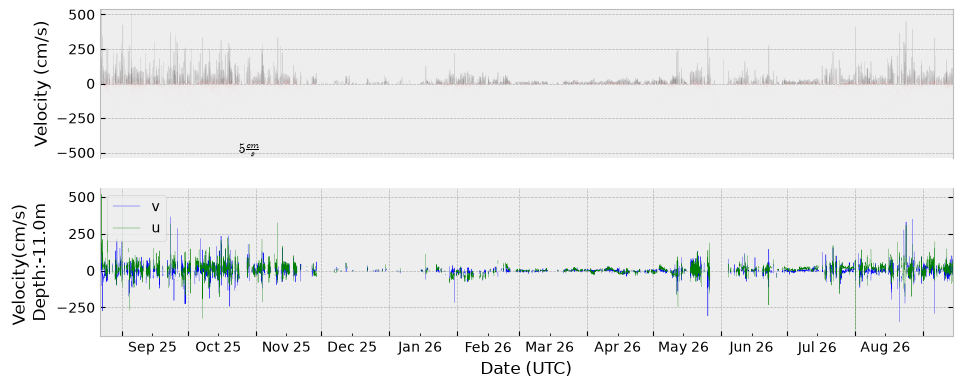

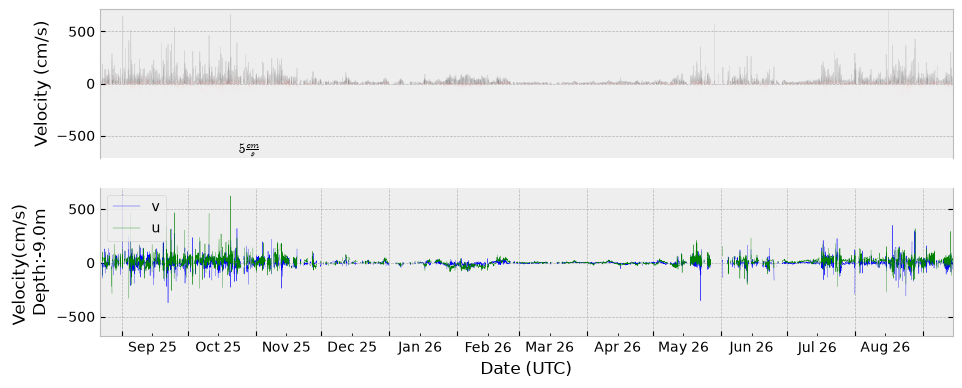

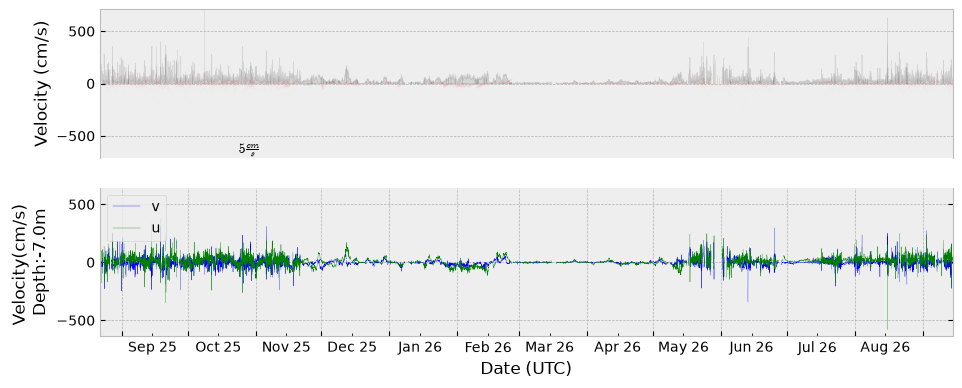

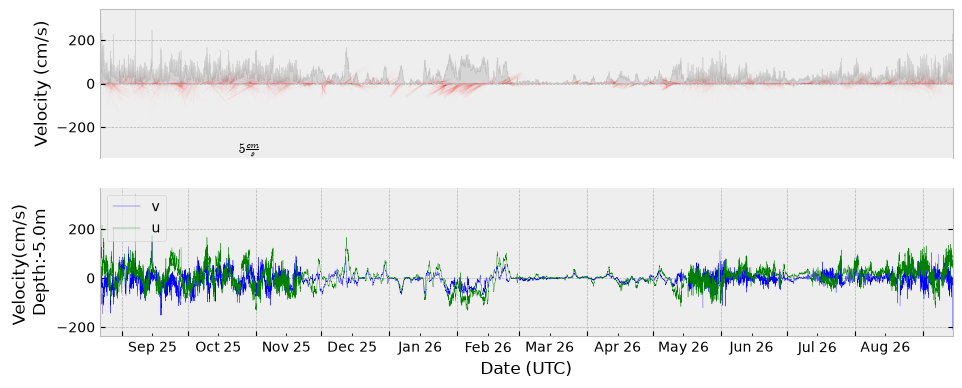

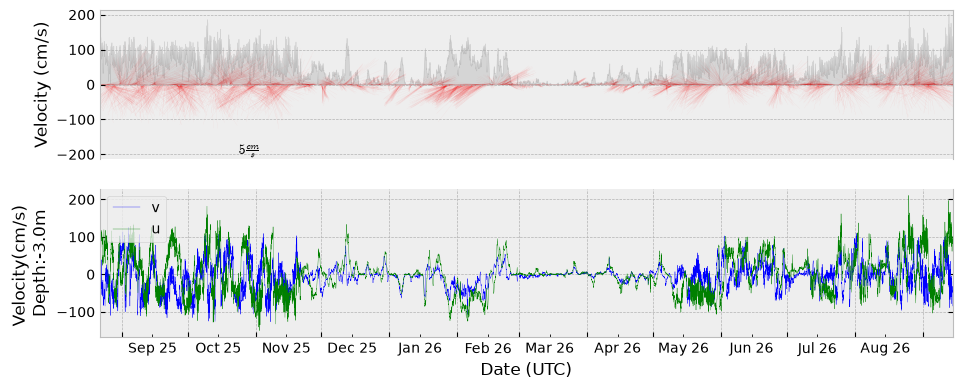

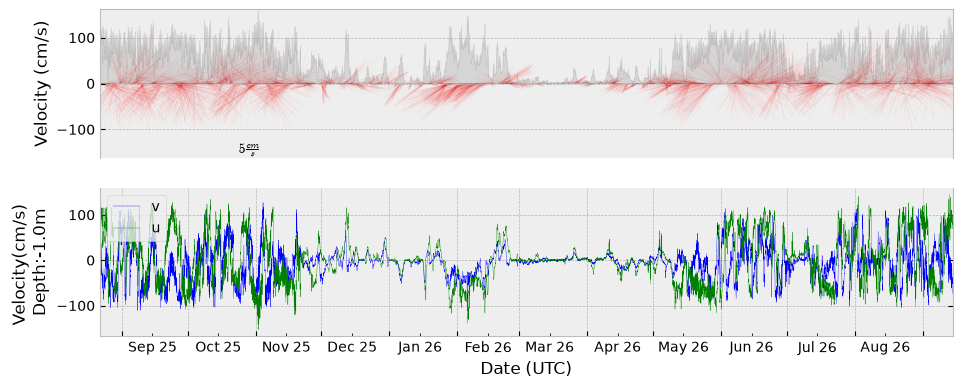

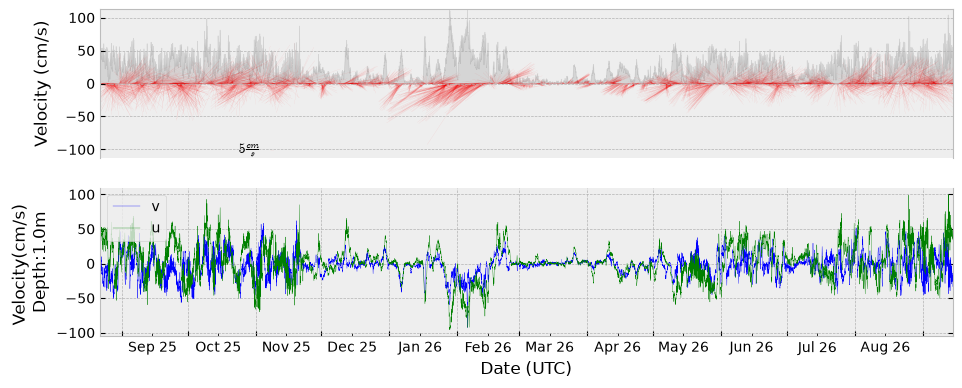

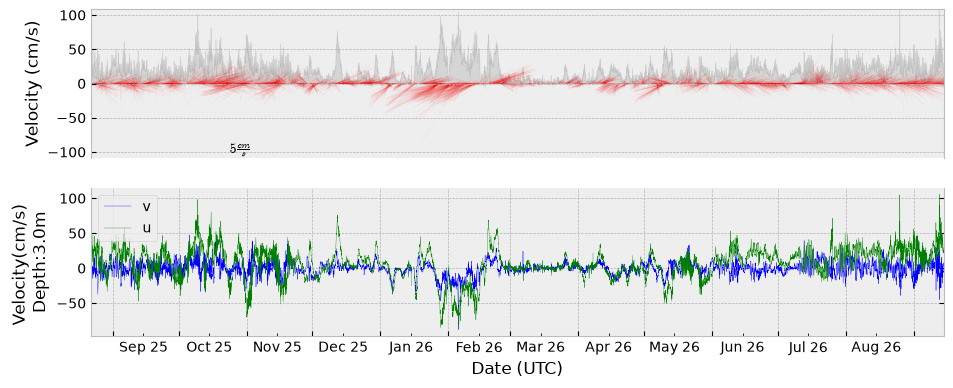

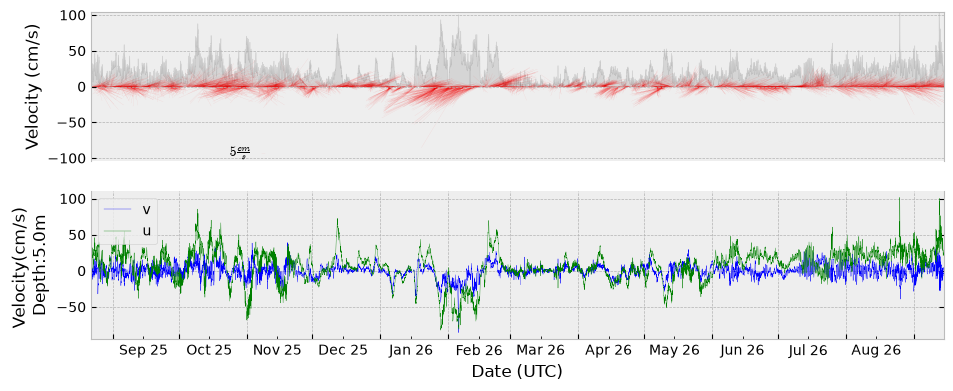

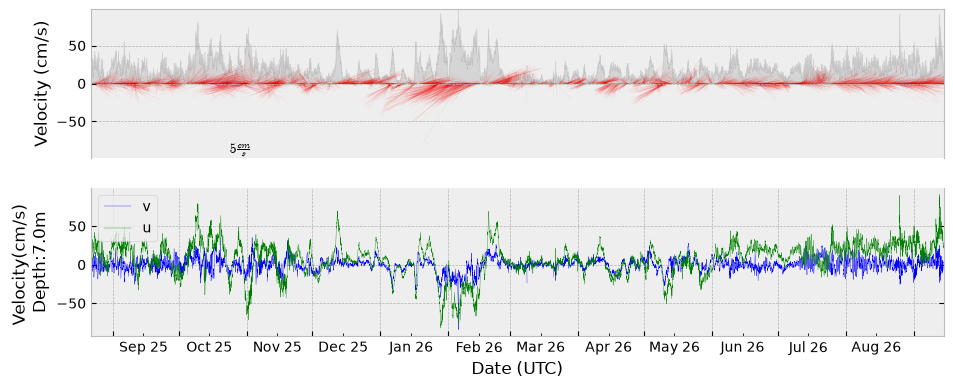

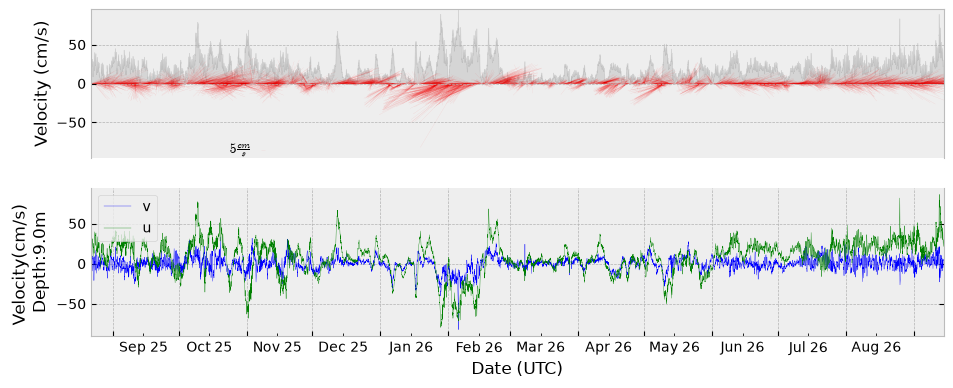

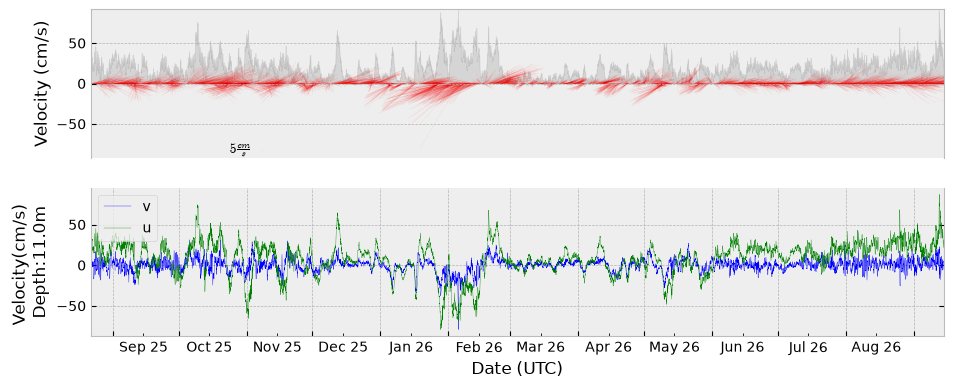

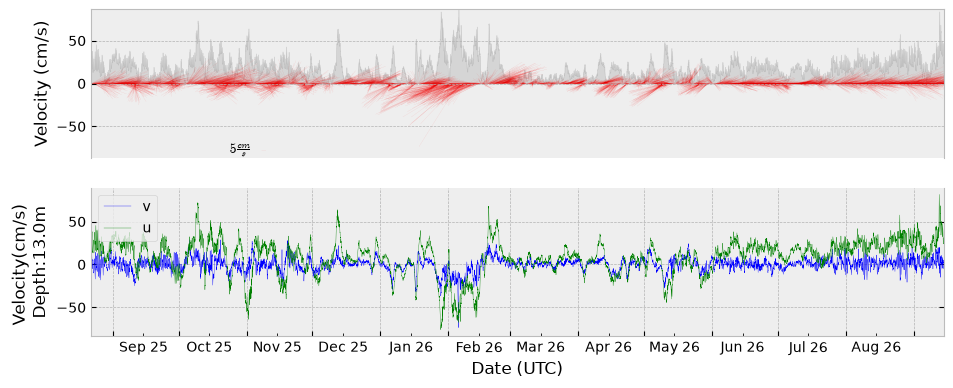

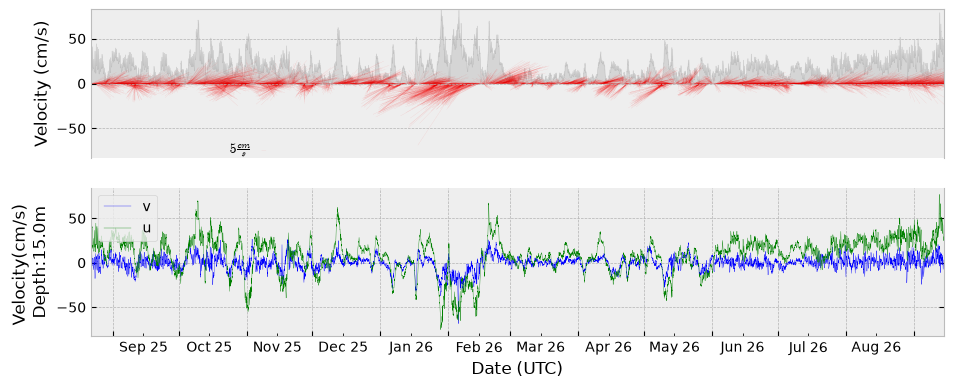

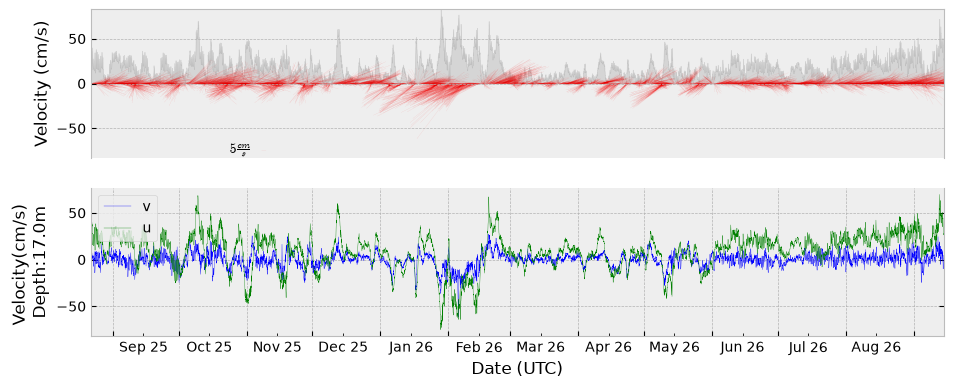

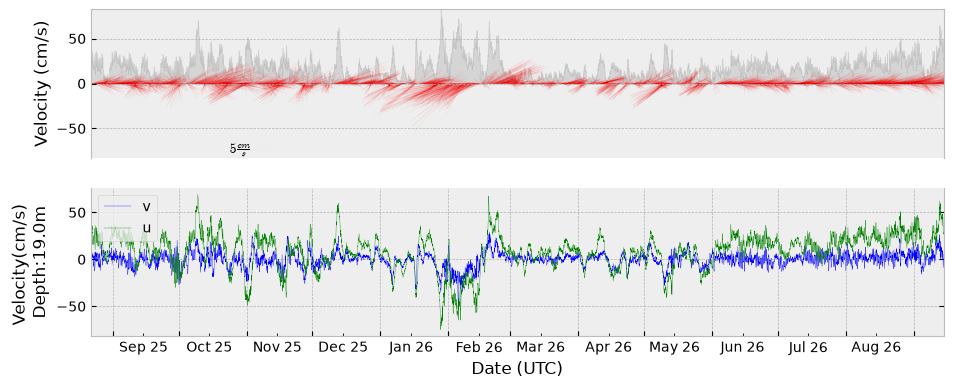

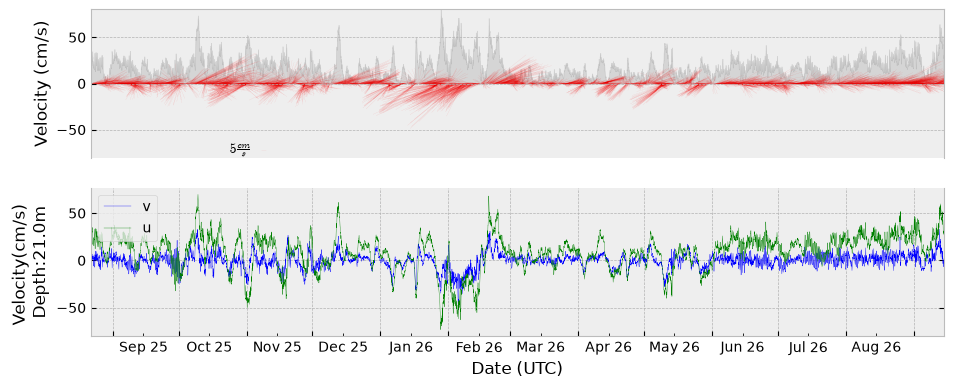

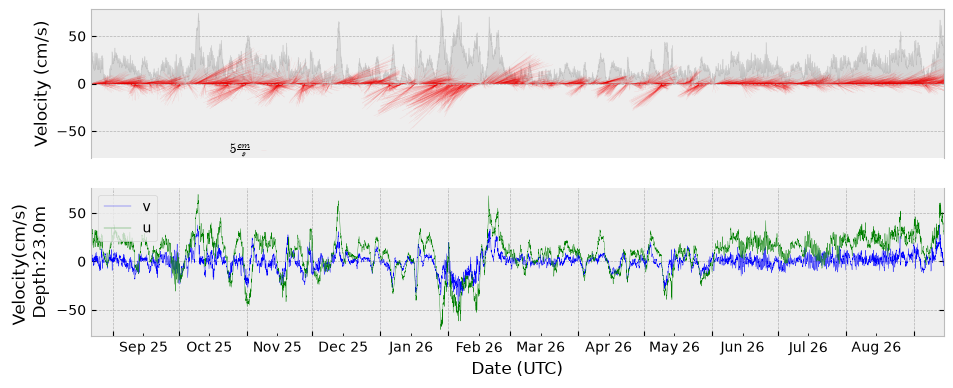

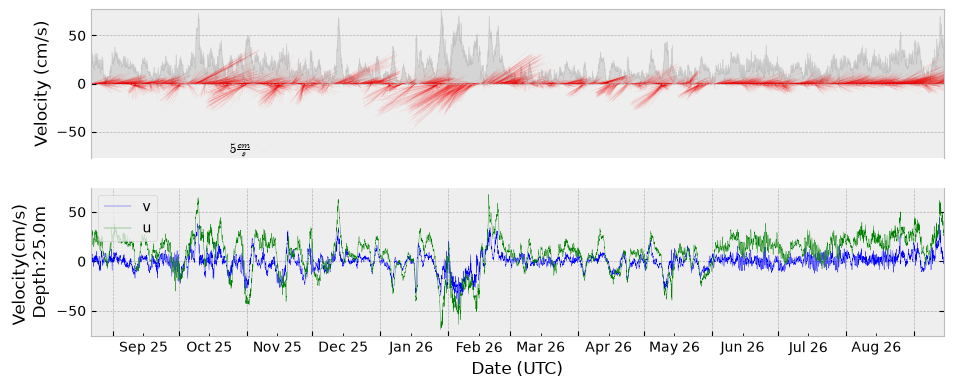

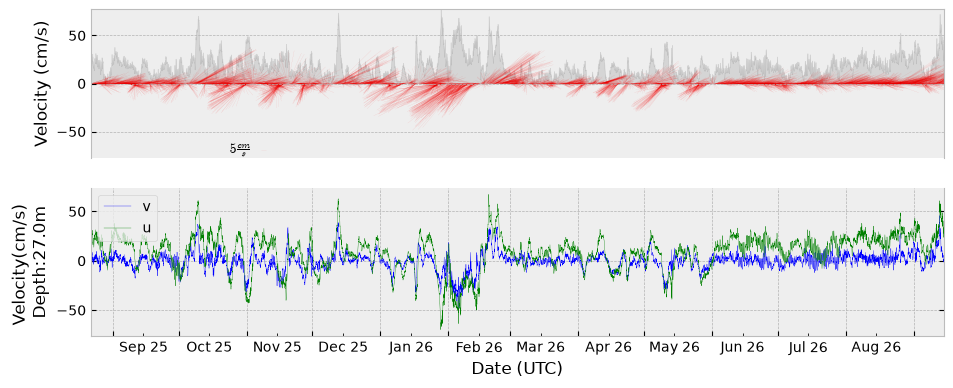

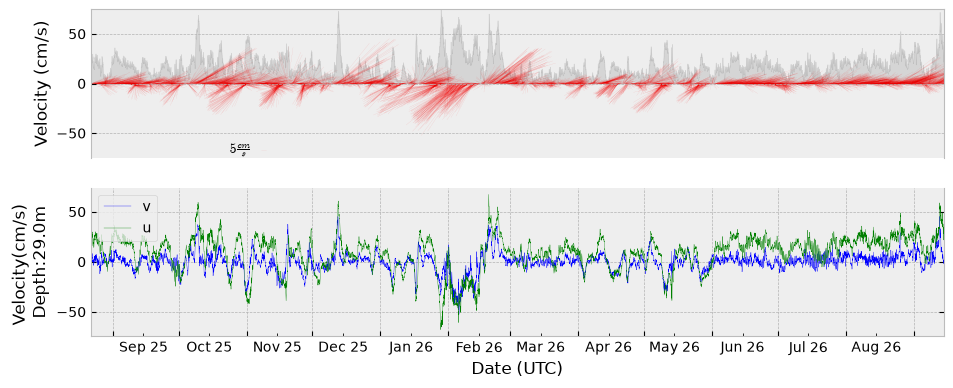

In [14]:
for i in range(0,len(xdf.depth),1):
    try:
        p1 = TimeSeriesStickPlot.Timeseries1dStickPlot()
        plt1, fig1 = p1.plot(timedata=xdf.time, 
                         udata=xdf.isel(depth=i,latitude=0,longitude=0).u_curr_comp, 
                         vdata=xdf.isel(depth=i,latitude=0,longitude=0).v_curr_comp,
                         rotate=0,
                         ylabel = f'Velocity(cm/s) \n {xdf.isel(depth=i).depth.values}m ')
        plt1.ylabel(f'Velocity(cm/s) \n Depth:{xdf.isel(depth=i).depth.values}m ')
    except:
        pass

In [13]:
xdf =xdf.where(np.abs(xdf.u_curr_comp) <=750,np.nan)
xdf =xdf.where(np.abs(xdf.v_curr_comp) <=750,np.nan)
xdf

<xarray.Dataset> Size: 13MB
Dimensions:          (latitude: 1, longitude: 1, time: 9325, depth: 22)
Coordinates:
  * latitude         (latitude) float64 8B 70.84
  * longitude        (longitude) float64 8B -163.1
  * time             (time) datetime64[ns] 75kB 2025-08-22T03:00:00 ... 2026-...
  * depth            (depth) float64 176B -13.0 -11.0 -9.0 ... 25.0 27.0 29.0
Data variables:
    u_curr_comp      (latitude, longitude, time, depth) float64 2MB -70.23 .....
    v_curr_comp      (latitude, longitude, time, depth) float64 2MB 127.4 ......
    w_curr_comp      (latitude, longitude, time, depth) float64 2MB 26.6 ... ...
    w_curr_comp_err  (latitude, longitude, time, depth) float64 2MB nan ... 0.7
    agc1             (latitude, longitude, time, depth) float64 2MB 53.0 ... ...
    agc2             (latitude, longitude, time, depth) float64 2MB 44.0 ... ...
    agc3             (latitude, longitude, time, depth) float64 2MB 47.0 ... ...
    agc4             (latitude, longitude, time, depth) float64 2MB 48.0 ... ...
Attributes: (12/13)
    Latitude_DegMMddW:                      70 50.184 N
    Longitude_DegMMddN:                     163 7.134 W
    MooringID:                              25CKP-1A
    platform_deployment_date:               2025-08-22T02:13:29Z
    platform_deployment_cruise_name:        SKQ202515S
    platform_recovery_date:                 2026-09-14T16:00:00Z
    ...                                     ...
    platform_deployment_recovery_comments:  
    WaterDepth:                             45.0
    date_created:                           2026-10-13T11:04:46Z
    date_modified:                          
    QC_indicator:                           unknown
    history:                                Trimmed to deployment.

In [7]:
# xdf['history'] = xdf.history + 'QC of high u/v values'

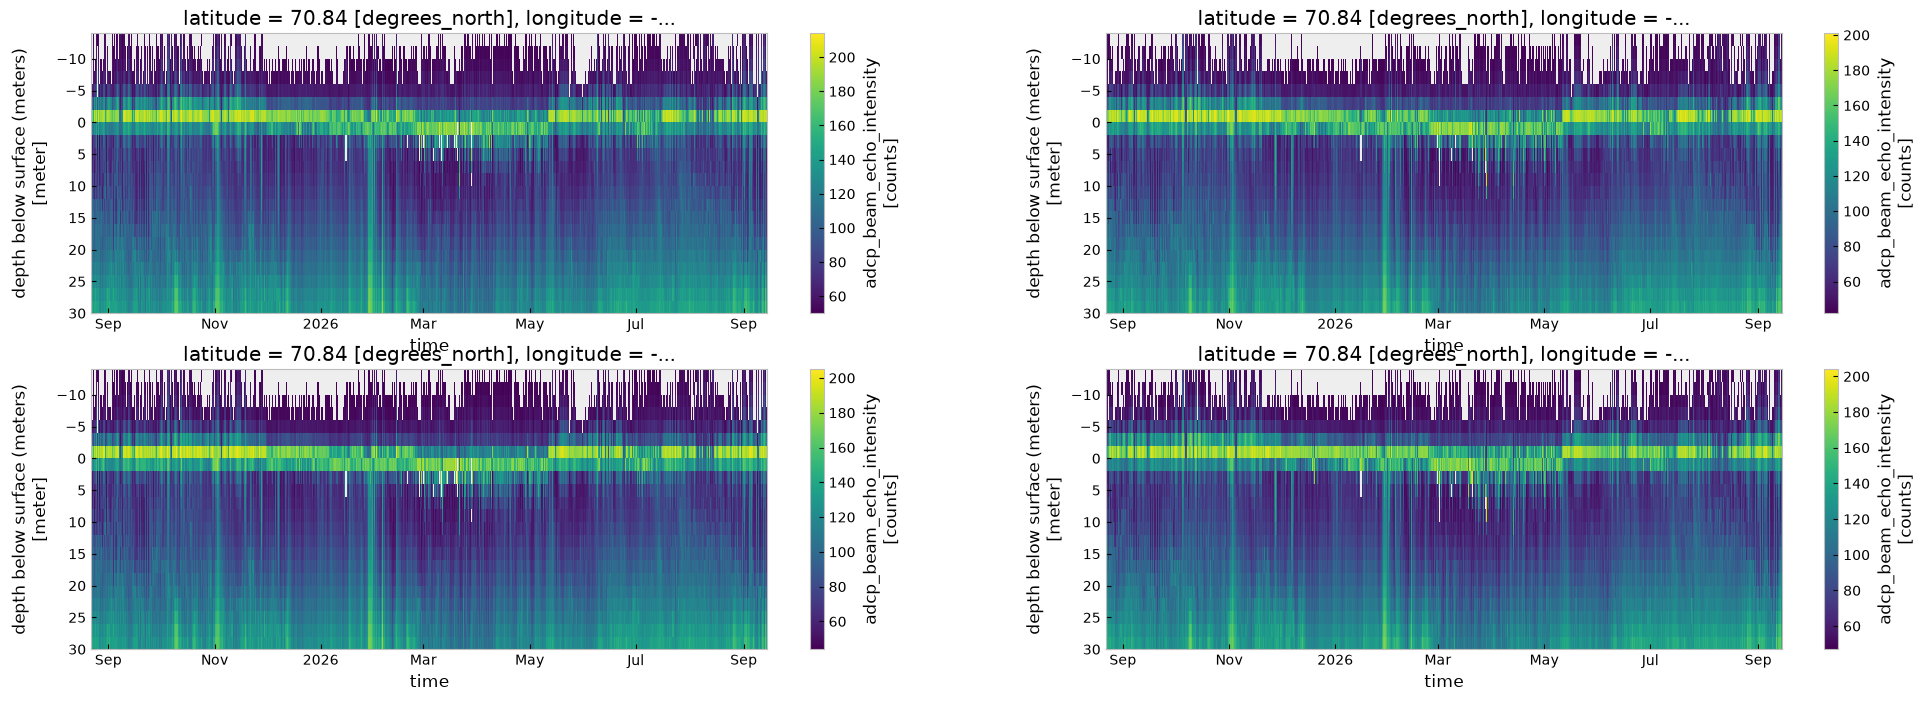

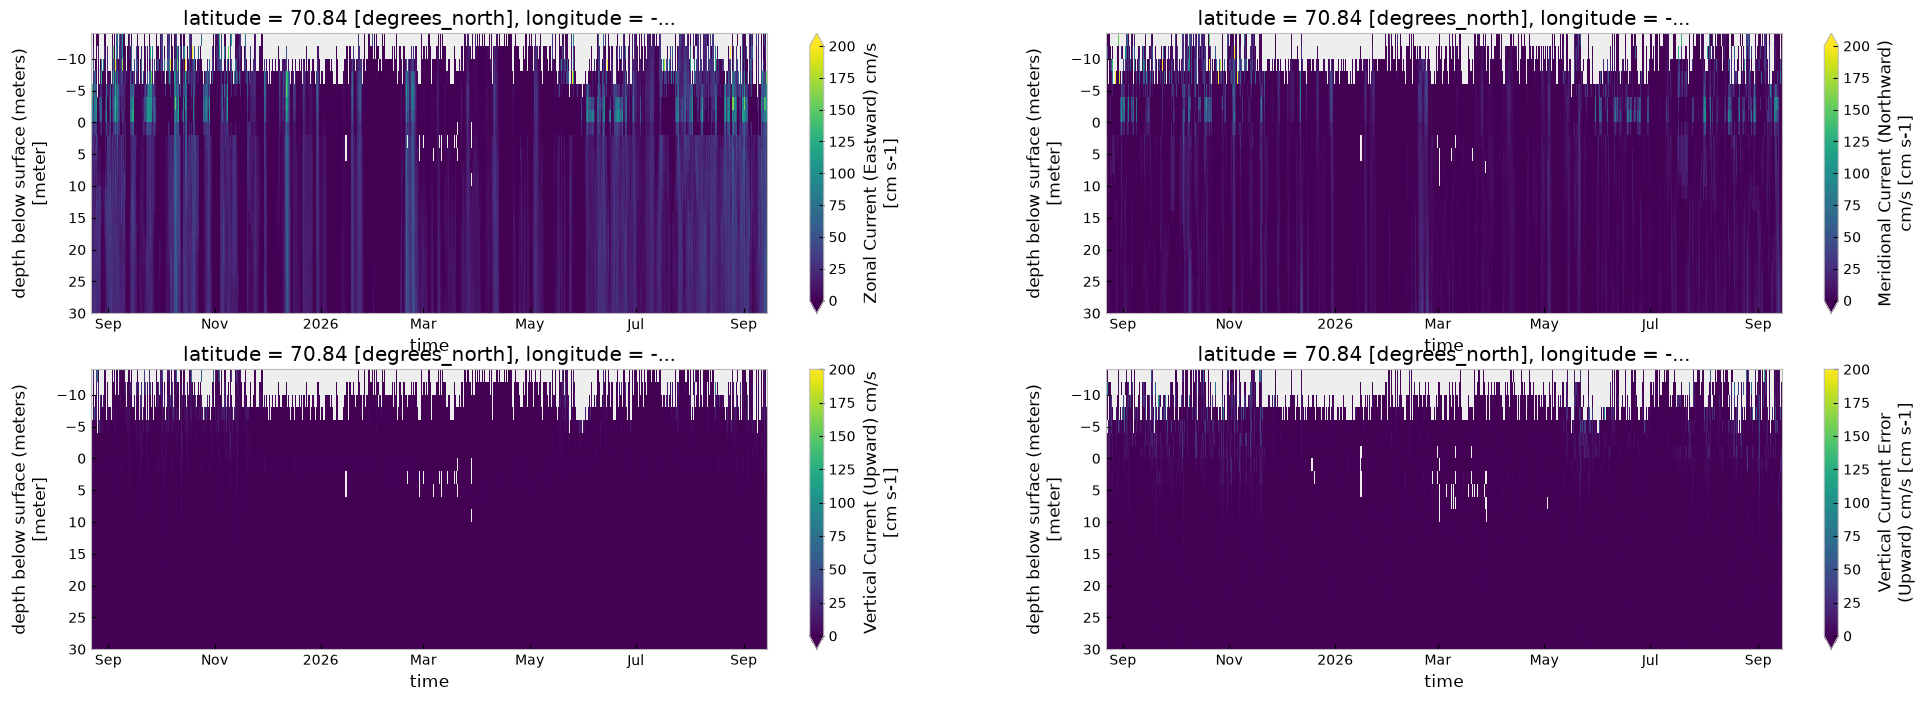

In [6]:
#optional plotting

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    xdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    xdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    xdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    xdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [9]:
try:
    xdf.attrs['history'] = xdf.attrs['history']+'  removed U,V >750cm/s'
except:
    xdf.attrs['history'] = '  removed U,V >750cm/s'    

## Trim above surface (negative values)

In [15]:
ixdf = xdf.where(xdf.depth >=-0.).dropna(how='all',dim='depth')

In [16]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  trimmed above surface'

In [17]:
ixdf.to_netcdf('25ckp1a_0032m.trimmed.nc')

In [18]:
xdf = xa.load_dataset('25ckp1a_0032m.trimmed.nc')

In [19]:
ixdf = xdf.interpolate_na(dim='time',max_gap='2H')

## Interpolate over singleton missing gaps linearly

In [20]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 1hour gaps'

In [21]:
ixdf = ixdf.interpolate_na(dim='depth',max_gap=3)

In [22]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 2 vertical bin'

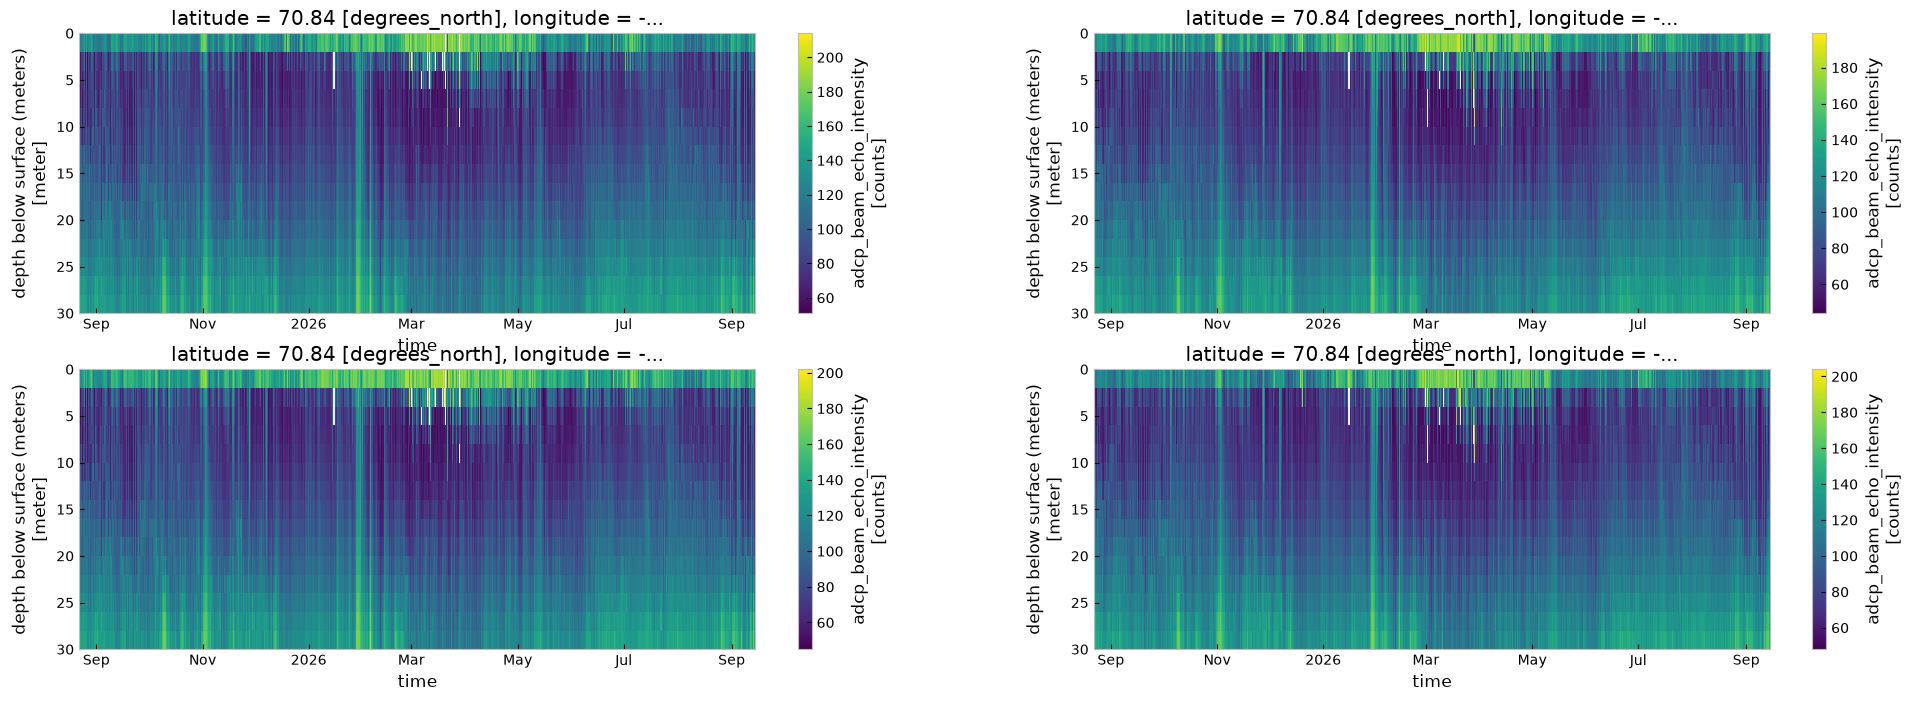

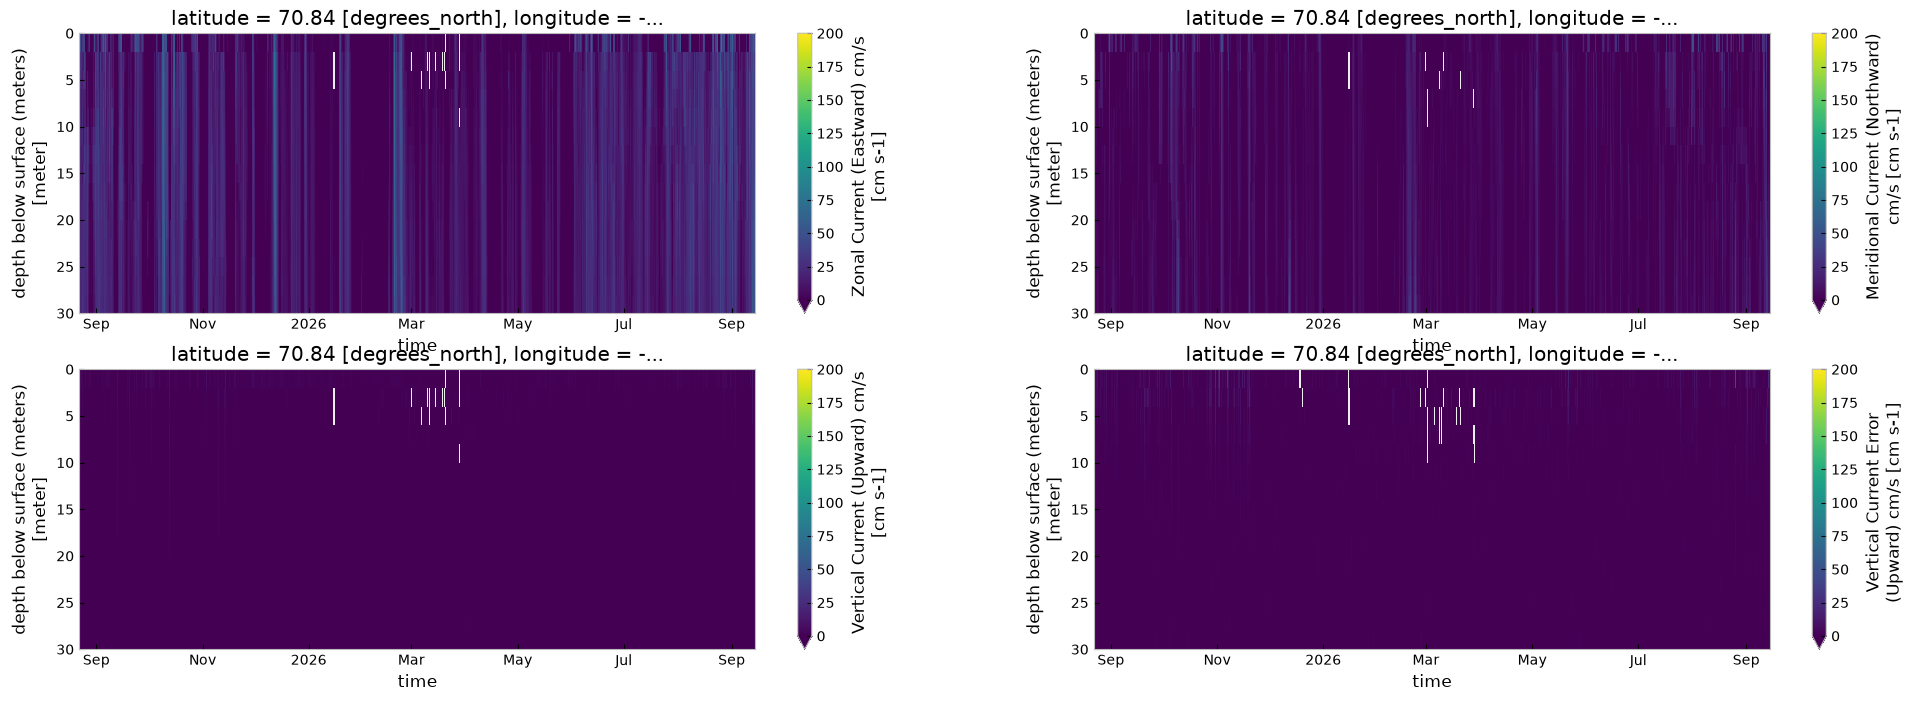

In [23]:

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    ixdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    ixdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    ixdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    ixdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [24]:
ixdf.to_netcdf('25ckp1a_0032m.filtered.nc')